# Análisis de Burnout en Desarrolladores — Limpieza + Regresión (sin StatsModels)

**Dataset:** `developer_burnout_dataset_7000.csv` (datos **crudos**, con valores faltantes e inconsistencias).

**Objetivo:** predecir `stress_level` (0–100) a partir de hábitos de trabajo y descanso, y entender qué variables influyen más.

**Etapas:**
1. Carga
2. Diagnóstico de calidad (¿qué tan sucio está el dataset?)
3. Limpieza
4. Exploración (EDA) con los datos limpios
5. Preparación para el modelo (`dropna()` + train/test)
6. Regresión lineal
7. Árbol de decisión y Random Forest
8. Consistencia de conclusiones (en lugar de p-valores)
9. Prueba de robustez
10. Diagnóstico de residuos
11. Conclusiones

Solo se usan herramientas vistas en clase: Pandas, NumPy, Matplotlib/Seaborn y scikit-learn. **No se usa StatsModels.**

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_style("whitegrid")
%matplotlib inline

## 1. Carga de datos
Funciona **en Jupyter local y en Google Colab**:
- En **local**: el CSV tiene que estar en la misma carpeta que este notebook.
- En **Colab**: si no encuentra el archivo, abre un botón para subirlo.

In [2]:
NOMBRE_CSV = "developer_burnout_dataset_7000.csv"

if not os.path.exists(NOMBRE_CSV):
    try:
        from google.colab import files      # solo existe en Colab
        print("Subí el archivo", NOMBRE_CSV)
        files.upload()
    except ImportError:
        raise FileNotFoundError(
            f"No encuentro {NOMBRE_CSV} en {os.getcwd()}. "
            "Copiá el CSV a esa carpeta o cambiá NOMBRE_CSV.")

df_raw = pd.read_csv(NOMBRE_CSV)
print("Filas y columnas:", df_raw.shape)
df_raw.head(10)

Filas y columnas: (7000, 12)


,age,experience_years,daily_work_hours,sleep_hours,caffeine_intake,bugs_per_day,commits_per_day,meetings_per_day,screen_time,exercise_hours,stress_level,burnout_level
0,26.0,12.0,10.33,4.45,2.0,11.0,4.0,1.0,15.07,0.14,55.96,Medium
1,39.0,10.0,8.62,5.77,5.0,15.0,11.0,5.0,13.25,0.54,82.22,High
2,34.0,13.0,NaN,4.03,5.0,2.0,18.0,9.0,11.18,1.54,61.77,Medium
3,30.0,1.0,6.85,6.47,2.0,15.0,26.0,1.0,11.14,0.96,54.98,Medium
4,27.0,7.0,4.24,5.80,NaN,9.0,17.0,7.0,8.05,0.36,27.90,Low
5,40.0,2.0,10.25,6.78,0.0,19.0,27.0,4.0,15.15,0.78,51.06,Medium
6,26.0,NaN,6.53,7.60,6.0,4.0,11.0,9.0,9.38,0.54,39.09,Medium
7,38.0,0.0,10.69,5.25,5.0,12.0,2.0,2.0,14.58,0.10,77.68,High
8,42.0,18.0,11.47,4.79,4.0,11.0,25.0,1.0,14.54,1.53,73.56,High
9,30.0,17.0,13.16,5.39,3.0,0.0,3.0,3.0,14.44,0.58,46.78,Medium


## 2. Diagnóstico de calidad: ¿qué tan sucio está el dataset?
Antes de limpiar hay que **medir** los problemas. Revisamos: tipos de datos, valores faltantes, duplicados, valores fuera de rango, categorías mal escritas, outliers y coherencia lógica entre columnas.

### 2.1 Tipos de datos

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               6860 non-null   float64
 1   experience_years  6860 non-null   float64
 2   daily_work_hours  6860 non-null   float64
 3   sleep_hours       6860 non-null   float64
 4   caffeine_intake   6860 non-null   float64
 5   bugs_per_day      6860 non-null   float64
 6   commits_per_day   6860 non-null   float64
 7   meetings_per_day  6860 non-null   float64
 8   screen_time       6860 non-null   float64
 9   exercise_hours    6860 non-null   float64
 10  stress_level      6860 non-null   float64
 11  burnout_level     6860 non-null   str    
dtypes: float64(11), str(1)
memory usage: 656.4 KB


Todas las columnas numéricas son `float64` y `burnout_level` es texto (categoría Low / Medium / High).

### 2.2 Valores faltantes por columna

In [4]:
faltantes = pd.DataFrame({
    "faltantes": df_raw.isnull().sum(),
    "% faltantes": (df_raw.isnull().mean() * 100).round(2),
})
faltantes

,faltantes,% faltantes
age,140,2.0
experience_years,140,2.0
daily_work_hours,140,2.0
sleep_hours,140,2.0
caffeine_intake,140,2.0
bugs_per_day,140,2.0
commits_per_day,140,2.0
meetings_per_day,140,2.0
screen_time,140,2.0
exercise_hours,140,2.0


### 2.3 Valores faltantes por fila
Que cada columna tenga solo un 2% de vacíos no significa que se pierda solo un 2% de las filas: depende de si los vacíos caen **en las mismas filas o en filas distintas**.

In [5]:
nulos_por_fila = df_raw.isnull().sum(axis=1)
print("Cantidad de filas según cuántos vacíos tienen:")
print(nulos_por_fila.value_counts().sort_index().rename_axis("vacíos en la fila").to_string())

filas_con_nulos = (nulos_por_fila > 0).sum()
print(f"\nFilas completas: {(nulos_por_fila == 0).sum()}")
print(f"Filas con al menos un vacío: {filas_con_nulos} ({filas_con_nulos / len(df_raw):.1%})")

Cantidad de filas según cuántos vacíos tienen:
vacíos en la fila
0    5490
1    1352
2     146
3      12

Filas completas: 5490
Filas con al menos un vacío: 1510 (21.6%)


**Hallazgo:** los vacíos están **dispersos en filas distintas**. Usar `dropna()` (borrar toda fila con algún vacío) sobre el dataset tal como viene eliminaría **más del 20% de las filas**, no un 2%.

Igual elegimos `dropna()` para el modelo (sección 5), porque así entrena **solo con datos reales**, sin valores inventados. Para perder lo menos posible, antes **recuperamos lo que se puede recuperar sin inventar**: `burnout_level` se reconstruye con su regla exacta (sección 3.2). Así no se borra ninguna fila solo por faltarle esa columna, que además no se usa en el modelo.

### 2.4 Filas duplicadas

In [6]:
print("Filas duplicadas:", df_raw.duplicated().sum())

Filas duplicadas: 0


### 2.5 Valores fuera de rango
Definimos qué valores son **posibles en la realidad** para cada variable y contamos cuántos se salen de esos límites.

In [7]:
RANGOS = {
    "age": (18, 70),
    "experience_years": (0, 50),
    "daily_work_hours": (0, 24),
    "sleep_hours": (0, 24),
    "caffeine_intake": (0, 20),
    "bugs_per_day": (0, 200),
    "commits_per_day": (0, 200),
    "meetings_per_day": (0, 24),
    "screen_time": (0, 24),
    "exercise_hours": (0, 24),
    "stress_level": (0, 100),
}

fuera = []
for col, (minimo, maximo) in RANGOS.items():
    s = df_raw[col].dropna()
    fuera.append({"variable": col, "mín. permitido": minimo, "máx. permitido": maximo,
                  "mín. real": s.min(), "máx. real": s.max(),
                  "fuera de rango": int(((s < minimo) | (s > maximo)).sum())})
pd.DataFrame(fuera)

,variable,mín. permitido,máx. permitido,mín. real,máx. real,fuera de rango
0,age,18,70,20.00,44.00,0
1,experience_years,0,50,0.00,19.00,0
2,daily_work_hours,0,24,4.00,14.00,0
3,sleep_hours,0,24,4.00,9.00,0
4,caffeine_intake,0,20,0.00,7.00,0
5,bugs_per_day,0,200,0.00,19.00,0
6,commits_per_day,0,200,0.00,29.00,0
7,meetings_per_day,0,24,0.00,9.00,0
8,screen_time,0,24,5.21,18.93,0
9,exercise_hours,0,24,0.00,2.00,0


In [8]:
# Variables que son conteos: deberían ser números enteros
conteos = ["age", "experience_years", "caffeine_intake", "bugs_per_day", "commits_per_day", "meetings_per_day"]
for col in conteos:
    print(f"{col}: {int((df_raw[col].dropna() % 1 != 0).sum())} valores con decimales")

age: 0 valores con decimales
experience_years: 0 valores con decimales
caffeine_intake: 0 valores con decimales
bugs_per_day: 0 valores con decimales
commits_per_day: 0 valores con decimales
meetings_per_day: 0 valores con decimales


### 2.6 Categorías de texto
Revisamos si `burnout_level` tiene variantes mal escritas (espacios, mayúsculas, etc.).

In [9]:
df_raw["burnout_level"].value_counts(dropna=False)

burnout_level
Medium    3485
High      1782
Low       1593
NaN        140
Name: count, dtype: int64

### 2.7 Outliers (valores atípicos)
Usamos la **regla del rango intercuartílico (IQR)**: un valor es atípico si está muy por debajo del 25% inferior o muy por encima del 25% superior (más de 1.5 × IQR de distancia).

age                 0
experience_years    0
daily_work_hours    0
sleep_hours         0
caffeine_intake     0
bugs_per_day        0
commits_per_day     0
meetings_per_day    0
screen_time         0
exercise_hours      0
stress_level        0


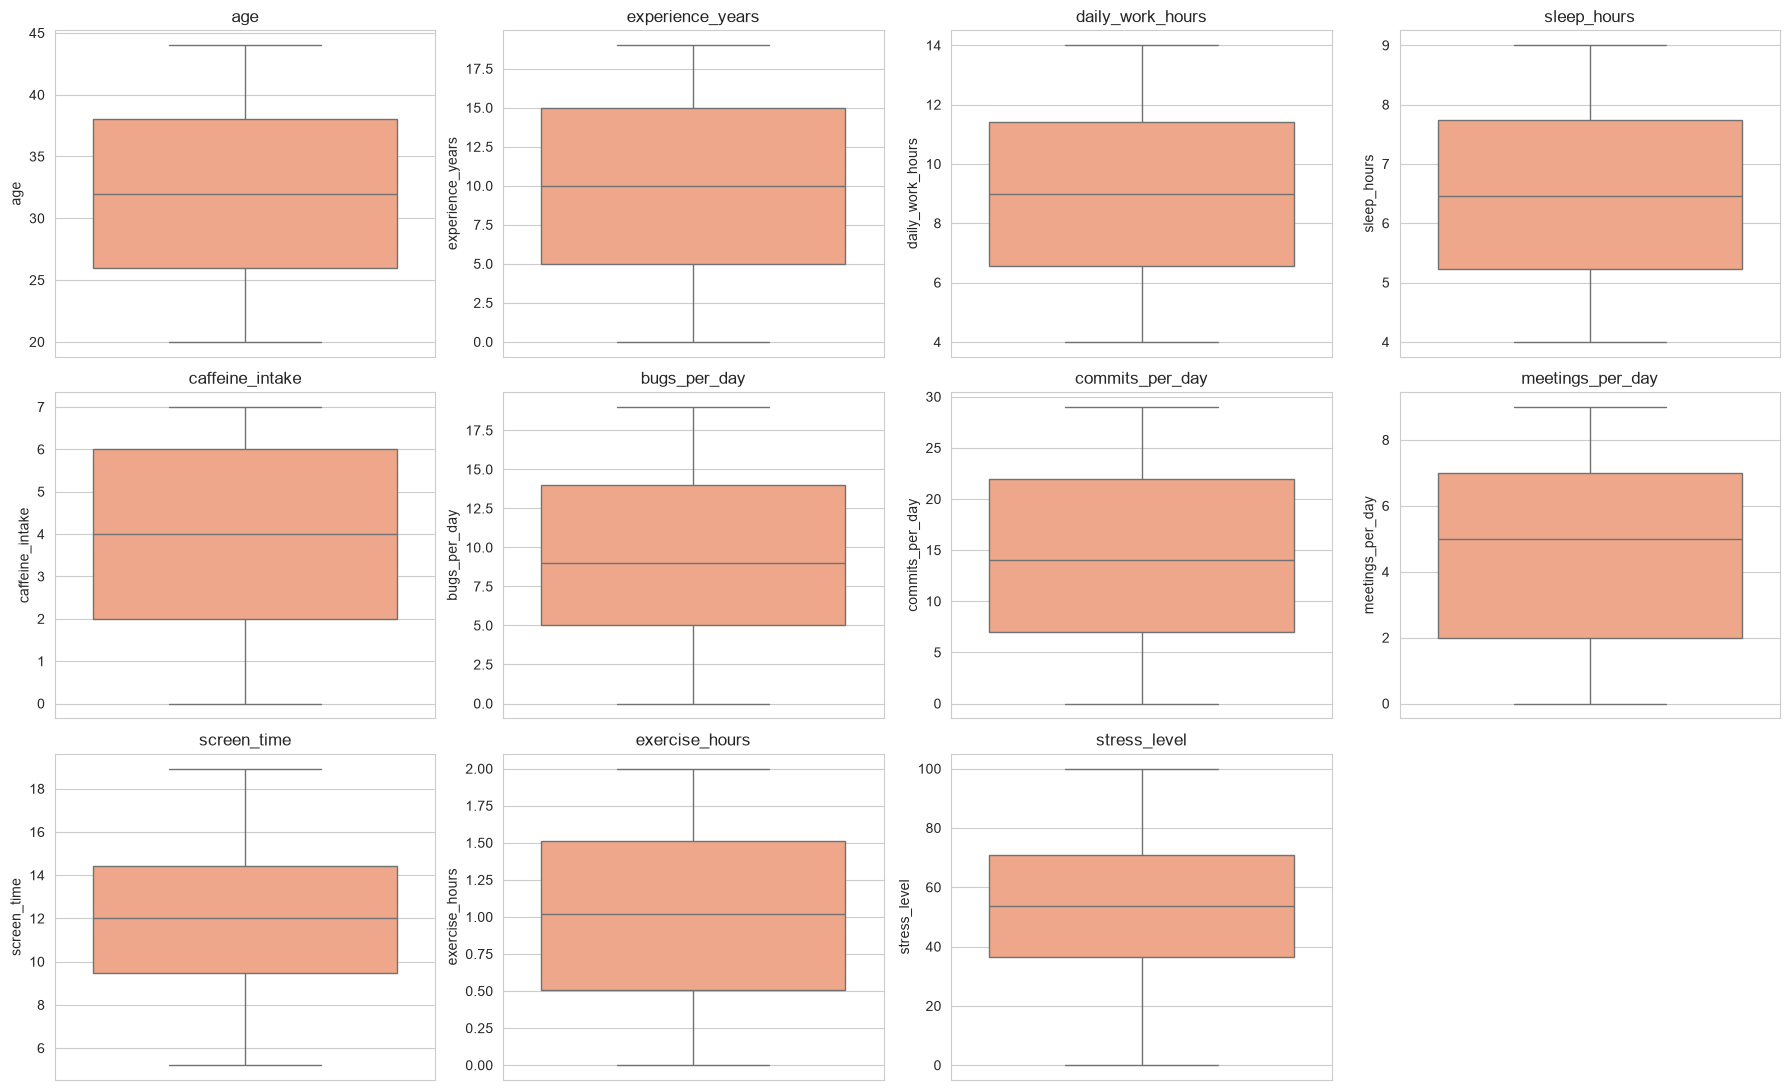

In [10]:
num_cols = df_raw.select_dtypes(include="number").columns.tolist()

outliers = {}
for col in num_cols:
    q1, q3 = df_raw[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers[col] = int(((df_raw[col] < q1 - 1.5 * iqr) | (df_raw[col] > q3 + 1.5 * iqr)).sum())
print(pd.Series(outliers, name="outliers (IQR)").to_string())

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(y=df_raw[col], ax=axes[i], color="lightsalmon")
    axes[i].set_title(col)
for j in range(len(num_cols), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

### 2.8 Coherencia lógica entre columnas
Un dato puede estar dentro de rango y aun así **no tener sentido combinado con otro**. Revisamos:
- ¿Alguien trabaja + duerme más de 24 horas?
- ¿El tiempo de pantalla es menor que las horas de trabajo? (un desarrollador trabaja frente a la pantalla)
- **Edad de inicio laboral** = edad − años de experiencia. ¿Hay personas que empezaron a trabajar siendo menores de edad?

Trabajo + sueño > 24 h: 0
Pantalla < horas de trabajo: 0

Edad a la que empezaron a trabajar (edad - experiencia):
count    6723.0
mean       22.6
std         9.2
min         1.0
25%        16.0
50%        23.0
75%        29.0
max        44.0

Empezaron antes de los 18: 1998
Empezaron antes de los 14: 1182


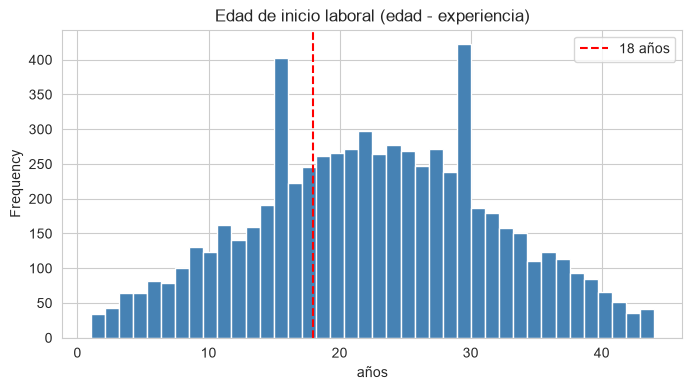

In [11]:
print("Trabajo + sueño > 24 h:", int((df_raw["daily_work_hours"] + df_raw["sleep_hours"] > 24).sum()))
print("Pantalla < horas de trabajo:", int((df_raw["screen_time"] < df_raw["daily_work_hours"]).sum()))

edad_inicio = df_raw["age"] - df_raw["experience_years"]
print("\nEdad a la que empezaron a trabajar (edad - experiencia):")
print(edad_inicio.describe().round(1).to_string())
print(f"\nEmpezaron antes de los 18: {int((edad_inicio < 18).sum())}")
print(f"Empezaron antes de los 14: {int((edad_inicio < 14).sum())}")

edad_inicio.plot.hist(bins=40, figsize=(8, 4), color="steelblue")
plt.axvline(18, color="red", ls="--", label="18 años")
plt.title("Edad de inicio laboral (edad - experiencia)")
plt.xlabel("años"); plt.legend()
plt.show()

### 2.9 Resumen del diagnóstico

| Problema | ¿Se encontró? | Qué hacemos |
|---|---|---|
| Valores faltantes | **Sí**: 140 por columna (2%), dispersos en el 21.6% de las filas | `burnout_level` vacío → se reconstruye con su regla. `stress_level` vacío → se elimina la fila. Predictoras vacías → se elimina la fila con `dropna()` (sección 5). |
| Duplicados | No | — |
| Fuera de rango | No | Se deja la validación igual, por si llegan datos nuevos. |
| Categorías mal escritas | No | Se normaliza el texto de forma preventiva. |
| Outliers | No | No hace falta recortar. |
| Inconsistencia edad/experiencia | **Sí**: muchas personas "empezaron a trabajar" siendo niños | Se marca con una columna y se mide si afecta (sección 9). |

## 3. Limpieza

Trabajamos sobre una **copia** para no modificar los datos originales.

### 3.1 Normalizar el texto de `burnout_level`
Sacamos espacios y unificamos mayúsculas (ej.: `" high"` → `"High"`). En este dataset no cambia nada, pero protege el análisis si llegan datos mal cargados.

In [12]:
df = df_raw.copy()
df["burnout_level"] = df["burnout_level"].str.strip().str.capitalize()
df["burnout_level"].value_counts(dropna=False)

burnout_level
Medium    3485
High      1782
Low       1593
NaN        140
Name: count, dtype: int64

### 3.2 Reconstruir `burnout_level` faltante a partir del estrés
`burnout_level` es una **categoría calculada a partir de `stress_level`**. Primero verificamos cuál es la regla exacta y que se cumpla en el 100% de las filas conocidas; recién ahí la usamos para completar las faltantes.

In [13]:
print(df.groupby("burnout_level")["stress_level"].agg(["min", "max", "count"]))

def nivel_burnout(estres):
    if pd.isna(estres):
        return np.nan
    if estres <= 35:
        return "Low"
    if estres > 70:
        return "High"
    return "Medium"

conocidos = df.dropna(subset=["stress_level", "burnout_level"])
coincide = (conocidos["stress_level"].apply(nivel_burnout) == conocidos["burnout_level"]).mean()
print(f"\nLa regla (Low ≤ 35 < Medium ≤ 70 < High) coincide en el {coincide:.1%} de los casos conocidos")

                 min     max  count
burnout_level                      
High           70.01  100.00   1758
Low             0.00   35.00   1559
Medium         35.02   69.97   3405

La regla (Low ≤ 35 < Medium ≤ 70 < High) coincide en el 100.0% de los casos conocidos


In [14]:
a_completar = df["burnout_level"].isna() & df["stress_level"].notna()
df.loc[a_completar, "burnout_level"] = df.loc[a_completar, "stress_level"].apply(nivel_burnout)
print("burnout_level reconstruidos:", int(a_completar.sum()))
print("burnout_level que siguen vacíos:", int(df["burnout_level"].isna().sum()), "(son filas sin stress_level)")

burnout_level reconstruidos: 138
burnout_level que siguen vacíos: 2 (son filas sin stress_level)


### 3.3 Eliminar filas sin `stress_level`
`stress_level` es lo que queremos predecir. **No se puede inventar la respuesta**: si la rellenáramos con la mediana, le estaríamos enseñando al modelo valores falsos. Estas filas se eliminan.

In [15]:
antes = len(df)
df = df.dropna(subset=["stress_level"]).reset_index(drop=True)
print(f"Filas: {antes} -> {len(df)} (eliminadas: {antes - len(df)})")

Filas: 7000 -> 6860 (eliminadas: 140)


### 3.4 Marcar la inconsistencia edad / experiencia
No borramos estas filas porque:
- Son demasiadas (borrarlas sería perder casi un tercio del dataset).
- No sabemos **cuál** de las dos columnas está mal (¿la edad o la experiencia?).
- Ninguna de las dos variables está relacionada con el estrés (lo vemos en el EDA).

En su lugar las **marcamos** con una columna `inconsistente_edad_exp` y en la sección 9 comprobamos si sacarlas cambia los resultados.

In [16]:
df["inconsistente_edad_exp"] = (df["age"] - df["experience_years"]) < 18
print("Filas marcadas como inconsistentes:", int(df["inconsistente_edad_exp"].sum()))

Filas marcadas como inconsistentes: 1959


### 3.5 Resumen: antes vs. después de la limpieza
Los vacíos que quedan en las predictoras se eliminan con `dropna()` en la sección 5.

In [17]:
resumen = pd.DataFrame({
    "Antes": [len(df_raw), int(df_raw.isnull().sum().sum()), int(df_raw["stress_level"].isna().sum()),
              int(df_raw["burnout_level"].isna().sum())],
    "Después": [len(df), int(df.drop(columns="inconsistente_edad_exp").isnull().sum().sum()),
                int(df["stress_level"].isna().sum()), int(df["burnout_level"].isna().sum())],
}, index=["Filas", "Celdas vacías (total)", "stress_level vacíos", "burnout_level vacíos"])
resumen

,Antes,Después
Filas,7000,6860
Celdas vacías (total),1680,1365
stress_level vacíos,140,0
burnout_level vacíos,140,0


## 4. Exploración (EDA) con los datos limpios

### 4.1 Estadística descriptiva

In [18]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,6723.0,32.12,7.23,20.00,26.00,32.00,38.00,44.00
experience_years,6721.0,9.58,5.76,0.00,5.00,10.00,15.00,19.00
daily_work_hours,6721.0,9.00,2.87,4.00,6.56,8.99,11.43,14.00
sleep_hours,6725.0,6.48,1.44,4.00,5.22,6.44,7.73,9.00
caffeine_intake,6721.0,3.54,2.28,0.00,2.00,4.00,6.00,7.00
bugs_per_day,6723.0,9.50,5.75,0.00,5.00,9.00,14.00,19.00
commits_per_day,6726.0,14.43,8.67,0.00,7.00,14.00,22.00,29.00
meetings_per_day,6727.0,4.55,2.85,0.00,2.00,5.00,7.00,9.00
screen_time,6724.0,11.98,3.09,5.21,9.46,12.03,14.43,18.93
exercise_hours,6724.0,1.01,0.58,0.00,0.52,1.02,1.51,2.00


### 4.2 Distribución de cada variable

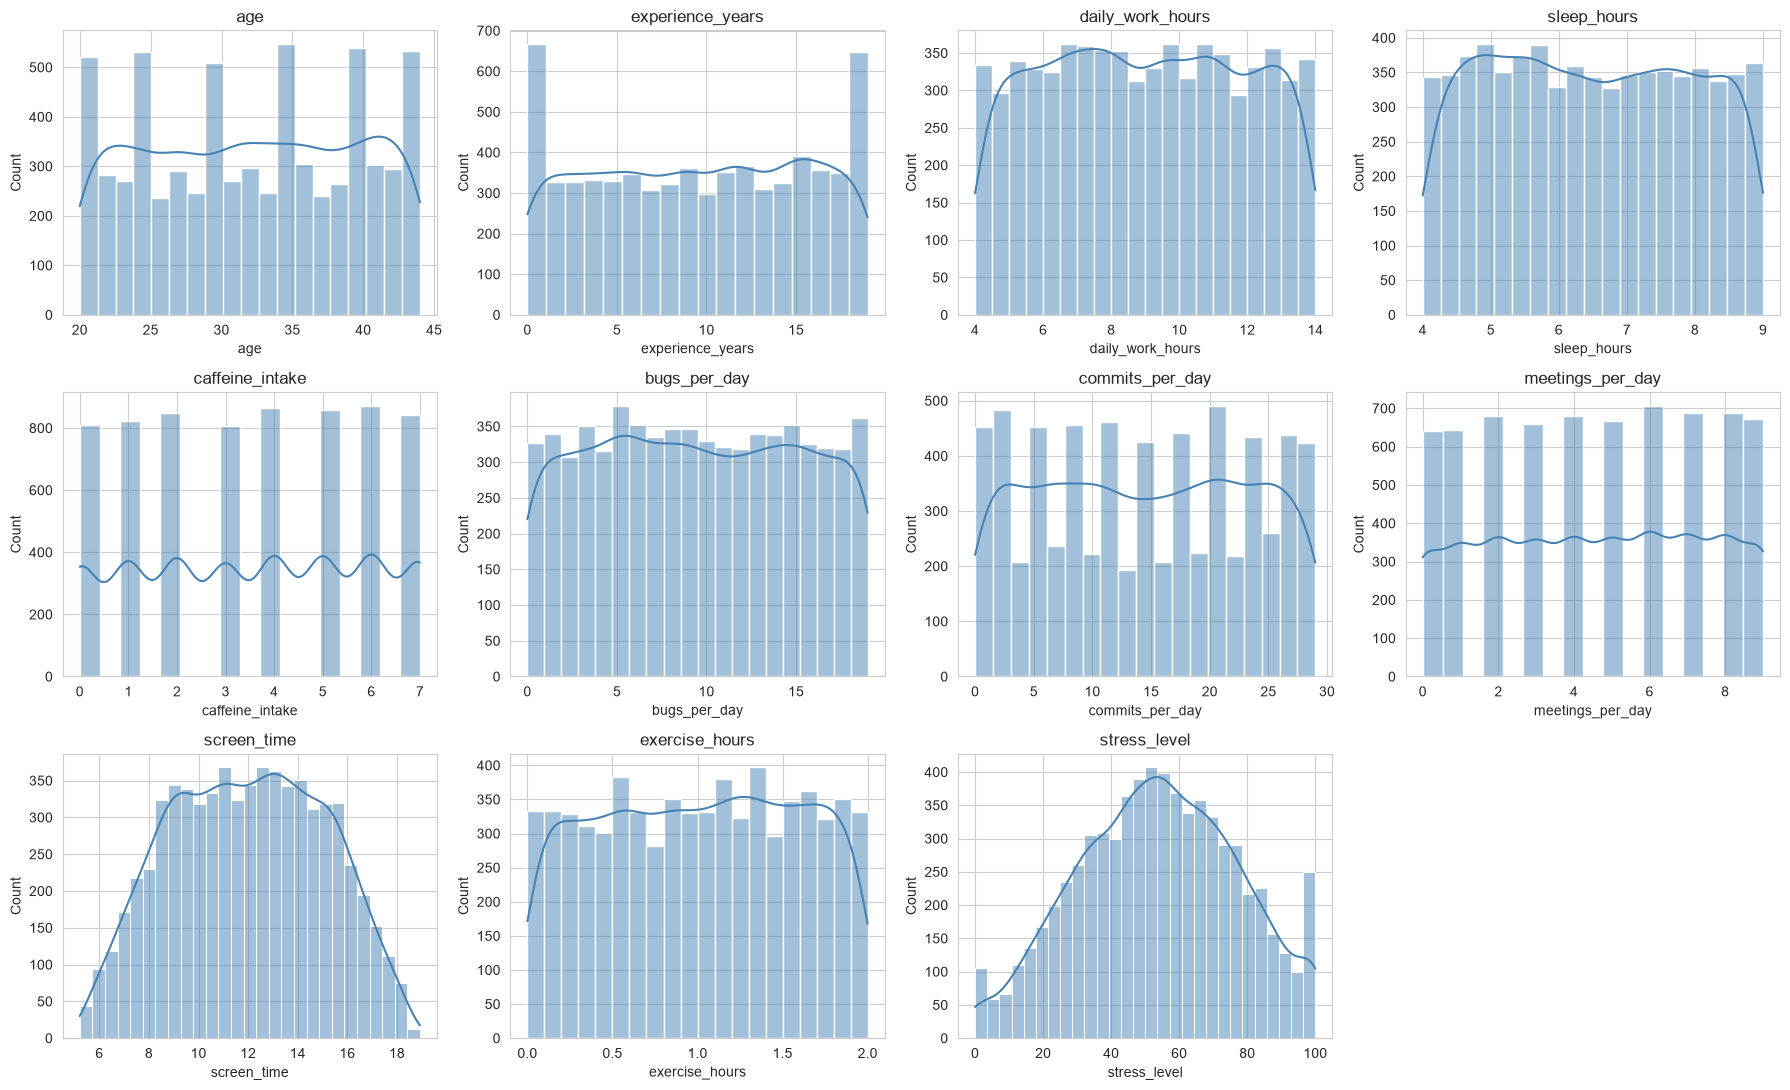

In [19]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(col)
for j in range(len(num_cols), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

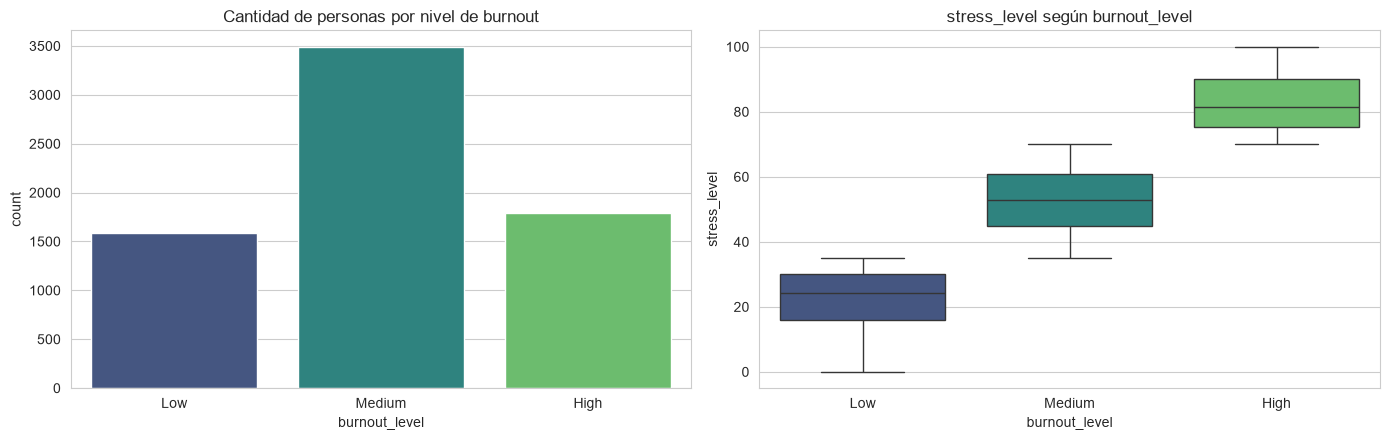

burnout_level
Medium    50.8
High      26.1
Low       23.1


In [20]:
orden = ["Low", "Medium", "High"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.countplot(data=df, x="burnout_level", order=orden, hue="burnout_level", hue_order=orden,
              palette="viridis", legend=False, ax=ax[0])
ax[0].set_title("Cantidad de personas por nivel de burnout")
sns.boxplot(data=df, x="burnout_level", y="stress_level", order=orden, hue="burnout_level", hue_order=orden,
            palette="viridis", legend=False, ax=ax[1])
ax[1].set_title("stress_level según burnout_level")
plt.tight_layout()
plt.show()
print((df["burnout_level"].value_counts(normalize=True) * 100).round(1).to_string())

### 4.3 Correlaciones
- **Rojo:** las variables suben juntas. **Azul:** cuando una sube, la otra baja. **Blanco:** sin relación.

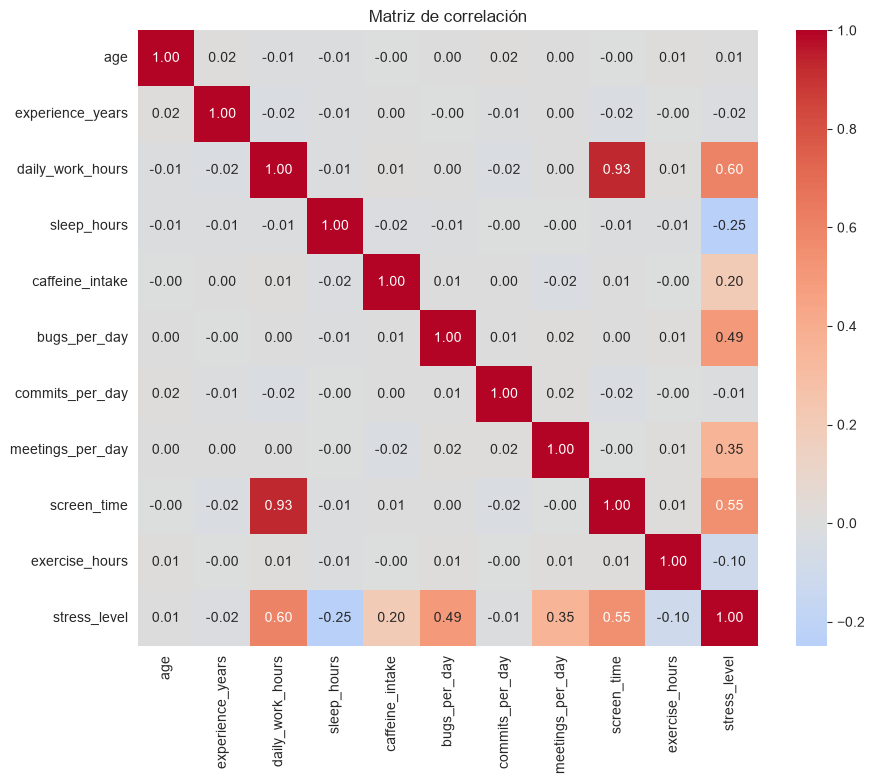

sleep_hours        -0.249907
exercise_hours     -0.104551
experience_years   -0.019935
commits_per_day    -0.007626
age                 0.006457
caffeine_intake     0.199618
meetings_per_day    0.351155
bugs_per_day        0.492421
screen_time         0.548701
daily_work_hours    0.600880
Name: stress_level, dtype: float64

In [21]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()

df[num_cols].corr()["stress_level"].drop("stress_level").sort_values()

## 5. Preparación para el modelo
- **Objetivo (y):** `stress_level`.
- **Predictoras (X):** las 10 variables de hábitos y contexto laboral.
- **Se excluye `burnout_level`:** está calculada a partir del estrés → usarla sería **data leakage** (darle al modelo la respuesta).

Receta:
1. Eliminamos las filas que todavía tienen algún vacío con `dropna()`: el modelo entrena **solo con datos reales**.
2. Dividimos en **train/test (80/20)**.

In [22]:
target = "stress_level"
features = ["age", "experience_years", "daily_work_hours", "sleep_hours", "caffeine_intake",
            "bugs_per_day", "commits_per_day", "meetings_per_day", "screen_time", "exercise_hours"]

df_model = df.dropna().copy()
print(f"Filas: {len(df)} -> {len(df_model)} (eliminadas por tener algún vacío: {len(df) - len(df_model)})")
print(f"Se conserva el {len(df_model) / len(df_raw):.1%} del dataset original")
print("Vacíos restantes:", int(df_model.isnull().sum().sum()))

X = df_model[features]
y = df_model[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("\nTrain:", X_train.shape, "| Test:", X_test.shape)

Filas: 6860 -> 5606 (eliminadas por tener algún vacío: 1254)
Se conserva el 80.1% del dataset original
Vacíos restantes: 0

Train: (4484, 10) | Test: (1122, 10)


### 5.1 ¿Borrar o imputar? Comparación
Comparamos nuestra estrategia (`dropna()`) contra la alternativa de **imputar**: rellenar los vacíos con la mediana calculada solo con train.

In [23]:
def metricas(nombre, y_real, y_pred):
    return {"Modelo": nombre,
            "R2": r2_score(y_real, y_pred),
            "MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_real, y_pred))}

# Nuestra estrategia: borrar filas con vacíos (dropna)
pred_drop = LinearRegression().fit(X_train, y_train).predict(X_test)

# Alternativa: imputar con la mediana de train
Xi_train, Xi_test, yi_train, yi_test = train_test_split(df[features], df[target], test_size=0.2, random_state=42)
medianas = Xi_train.median()          # solo con train
Xi_train, Xi_test = Xi_train.fillna(medianas), Xi_test.fillna(medianas)
pred_imp = LinearRegression().fit(Xi_train, yi_train).predict(Xi_test)

estrategias = pd.DataFrame([
    {**metricas("Borrar filas (dropna)", y_test, pred_drop), "Filas usadas": len(df_model)},
    {**metricas("Imputar con mediana", yi_test, pred_imp), "Filas usadas": len(df)},
]).round(4)
estrategias

,Modelo,R2,MAE,RMSE,Filas usadas
0,Borrar filas (dropna),0.8234,7.9714,9.9013,5606
1,Imputar con mediana,0.8019,8.1246,10.2469,6860


**Lectura:** con `dropna()` el modelo tiene mejores métricas (R² ≈ 0.82 vs. ≈ 0.80) porque aprende y se evalúa **solo con datos reales**. Imputar conservaría ~1.250 filas más, pero agrega valores estimados (la mediana) que no son el dato verdadero.

Elegimos **`dropna()`** porque:
- Aunque se pierden filas, **quedan más de 5.600 personas**, suficientes para entrenar con confianza.
- No se inventa ningún valor: todo lo que ve el modelo es dato real.
- Es más simple y transparente de explicar.

*Aclaración honesta: las dos estrategias se evalúan sobre tests distintos (el de `dropna()` solo tiene filas completas), así que la diferencia de R² es orientativa, no una prueba definitiva.*

## 6. Regresión lineal múltiple

In [24]:
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

res = [metricas("Regresión lineal", y_test, pred_lr)]
pd.DataFrame(res).round(4)

,Modelo,R2,MAE,RMSE
0,Regresión lineal,0.8234,7.9714,9.9013


### 6.1 Coeficientes (en unidades reales)
Como trabajamos con los datos **originales** (no normalizados), cada coeficiente se lee directo:
> "Si esta variable sube **1 unidad** (1 hora, 1 café, 1 reunión…), el estrés cambia en **X puntos** (sobre 100), manteniendo las demás constantes."

In [25]:
unidades = {"age": "año de edad", "experience_years": "año de experiencia", "daily_work_hours": "hora de trabajo",
            "sleep_hours": "hora de sueño", "caffeine_intake": "unidad de cafeína", "bugs_per_day": "bug por día",
            "commits_per_day": "commit por día", "meetings_per_day": "reunión por día",
            "screen_time": "hora de pantalla", "exercise_hours": "hora de ejercicio"}
coef_df = pd.DataFrame({"variable": features, "coeficiente": lr.coef_})
coef_df["lectura"] = [f"{c:+.2f} puntos de estrés por cada {unidades[v]} extra" for v, c in zip(features, lr.coef_)]
print("Intercepto:", round(lr.intercept_, 3))
coef_df.sort_values("coeficiente", key=abs, ascending=False).round(3)

Intercepto: 1.911


,variable,coeficiente,lectura
9,exercise_hours,-5.082,-5.08 puntos de estrés por cada hora de ejerci...
2,daily_work_hours,4.889,+4.89 puntos de estrés por cada hora de trabaj...
3,sleep_hours,-3.818,-3.82 puntos de estrés por cada hora de sueño ...
7,meetings_per_day,2.840,+2.84 puntos de estrés por cada reunión por dí...
4,caffeine_intake,2.044,+2.04 puntos de estrés por cada unidad de cafe...
5,bugs_per_day,1.932,+1.93 puntos de estrés por cada bug por día extra
1,experience_years,-0.051,-0.05 puntos de estrés por cada año de experie...
8,screen_time,-0.014,-0.01 puntos de estrés por cada hora de pantal...
6,commits_per_day,-0.011,-0.01 puntos de estrés por cada commit por día...
0,age,-0.007,-0.01 puntos de estrés por cada año de edad extra


### 6.2 Coeficientes estandarizados (comparación justa)
Los coeficientes crudos **no se pueden comparar entre sí**: "1 hora de ejercicio" y "1 commit" son cosas muy distintas, y el ejercicio varía entre 0 y 2 horas mientras los commits entre 0 y 29.
Con `StandardScaler` (`fit` en train, `transform` en test) todas las variables quedan en la misma escala y el tamaño del coeficiente sí indica importancia.

In [26]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lr_s = LinearRegression().fit(X_train_s, y_train)
coef_std = pd.DataFrame({"variable": features, "coef_estandarizado": lr_s.coef_})
coef_std = coef_std.sort_values("coef_estandarizado", key=abs, ascending=False)
print("R2 test (igual que antes, solo cambió la escala):", round(lr_s.score(X_test_s, y_test), 4))
coef_std.round(3)

R2 test (igual que antes, solo cambió la escala): 0.8234


,variable,coef_estandarizado
2,daily_work_hours,13.969
5,bugs_per_day,11.110
7,meetings_per_day,8.165
3,sleep_hours,-5.505
4,caffeine_intake,4.691
9,exercise_hours,-2.930
1,experience_years,-0.292
6,commits_per_day,-0.093
0,age,-0.049
8,screen_time,-0.044


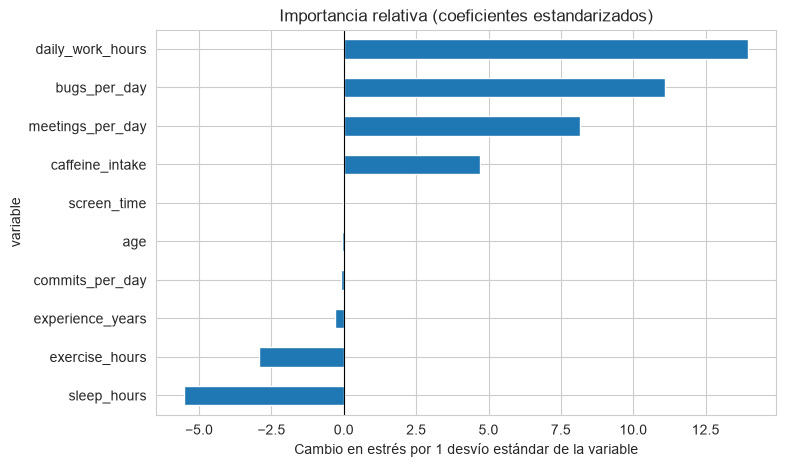

In [27]:
coef_std.sort_values("coef_estandarizado").plot.barh(x="variable", y="coef_estandarizado", legend=False, figsize=(8, 5))
plt.axvline(0, color="black", lw=0.8)
plt.title("Importancia relativa (coeficientes estandarizados)")
plt.xlabel("Cambio en estrés por 1 desvío estándar de la variable")
plt.show()

### 6.3 Multicolinealidad (VIF calculado con scikit-learn)
Si dos variables miden casi lo mismo (ej.: horas de trabajo y tiempo en pantalla), el modelo no puede repartir bien el efecto entre ellas.
**VIF = 1 / (1 − R²)** de predecir cada variable con las demás. Regla: VIF > 5 sospechoso, > 10 grave.

In [28]:
vif = []
for col in X_train.columns:
    otras = X_train.drop(columns=col)
    r2 = LinearRegression().fit(otras, X_train[col]).score(otras, X_train[col])
    vif.append({"variable": col, "VIF": 1 / (1 - r2)})
pd.DataFrame(vif).sort_values("VIF", ascending=False).round(2)

,variable,VIF
2,daily_work_hours,7.05
8,screen_time,7.05
7,meetings_per_day,1.00
3,sleep_hours,1.00
5,bugs_per_day,1.00
6,commits_per_day,1.00
4,caffeine_intake,1.00
0,age,1.00
1,experience_years,1.00
9,exercise_hours,1.00


## 7. Árbol de decisión y Random Forest
Usamos el **mismo split** train/test para que la comparación sea justa.

In [29]:
tree = DecisionTreeRegressor(max_depth=4, random_state=42).fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)

res.append(metricas("Árbol (depth=4)", y_test, tree.predict(X_test)))
res.append(metricas("Random Forest", y_test, rf.predict(X_test)))
tabla = pd.DataFrame(res).round(4)
tabla

,Modelo,R2,MAE,RMSE
0,Regresión lineal,0.8234,7.9714,9.9013
1,Árbol (depth=4),0.5860,12.4079,15.1594
2,Random Forest,0.7912,8.7683,10.7660


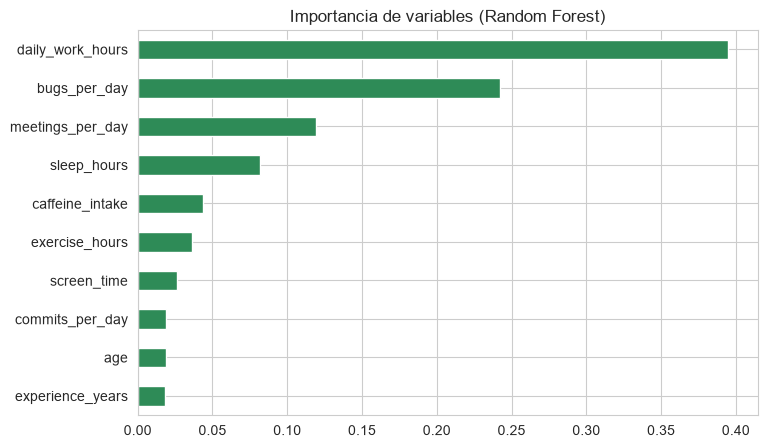

daily_work_hours    0.395
bugs_per_day        0.242
meetings_per_day    0.119
sleep_hours         0.082
caffeine_intake     0.044
exercise_hours      0.036
screen_time         0.026
commits_per_day     0.019
age                 0.019
experience_years    0.018
dtype: float64

In [30]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot.barh(figsize=(8, 5), color="seagreen")
plt.title("Importancia de variables (Random Forest)")
plt.show()
imp.sort_values(ascending=False).round(3)

### 7.1 Visualización del árbol
Cada recuadro es una pregunta ("¿horas de trabajo ≤ X?"). Siguiendo las ramas se llega a una predicción de estrés (`value`). Se muestran los 3 primeros niveles para que sea legible.

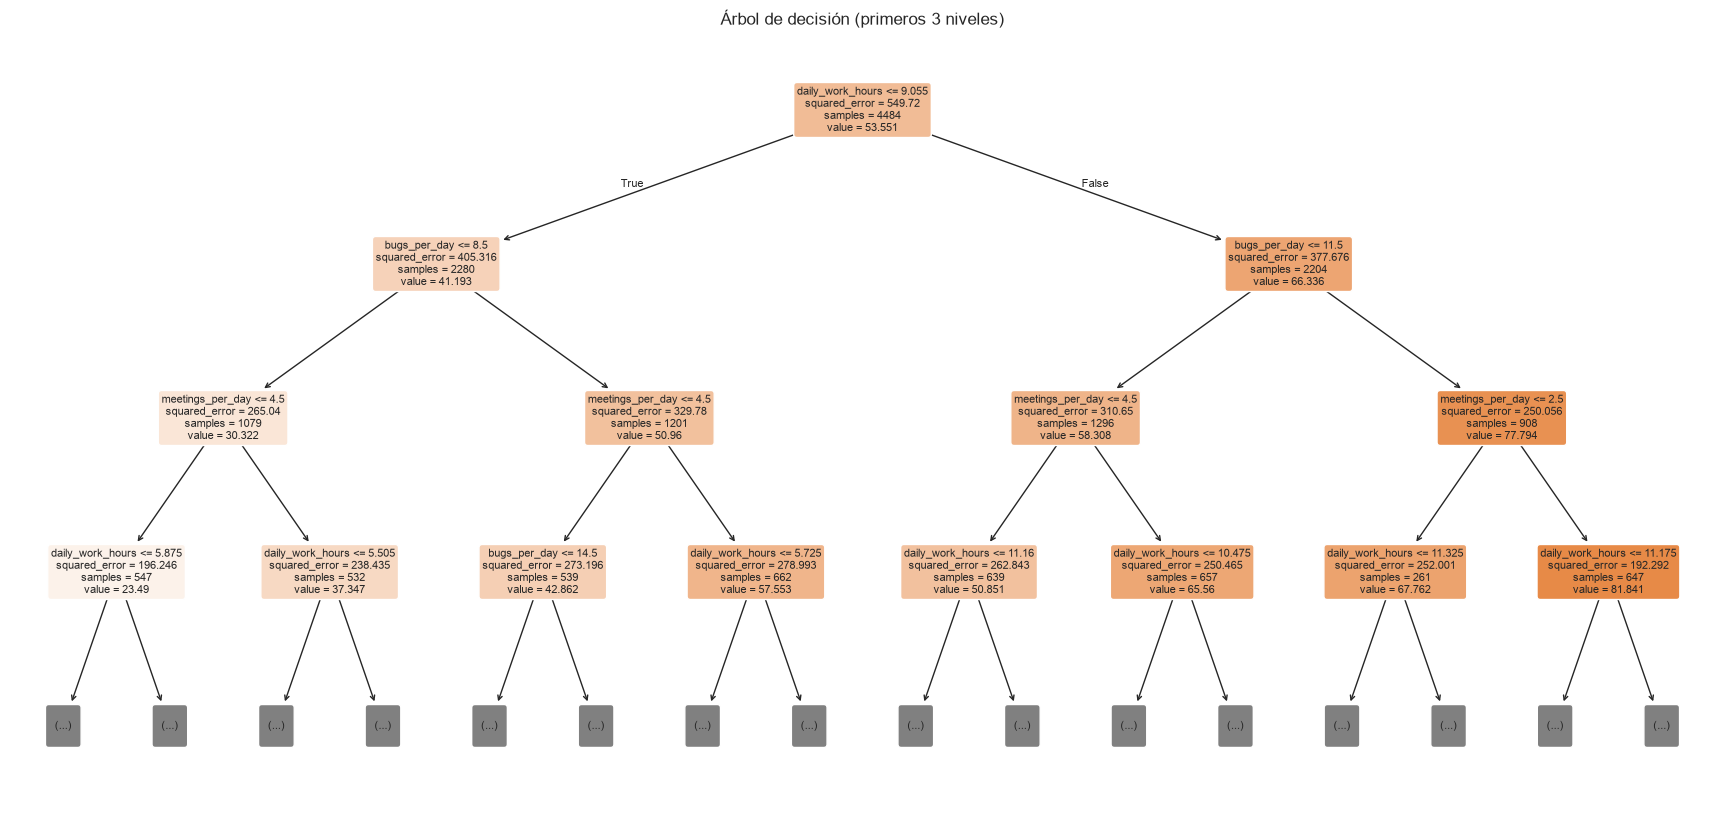

In [31]:
plt.figure(figsize=(22, 10))
plot_tree(tree, feature_names=features, filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title("Árbol de decisión (primeros 3 niveles)")
plt.show()

## 8. ¿Las conclusiones son consistentes? (en lugar de p-valores)
En vez de un test de significancia, **comparamos tres métodos distintos** para rankear la importancia de las variables. Si coinciden, la conclusión es robusta. (La correlación se calcula con train, para no mirar el test.)

In [32]:
comparacion = pd.DataFrame({
    "Corr. con estrés (abs)": X_train.corrwith(y_train).abs(),
    "Coef. estandarizado (abs)": pd.Series(np.abs(lr_s.coef_), index=features),
    "Importancia RF": pd.Series(rf.feature_importances_, index=features),
})
ranking = comparacion.rank(ascending=False).astype(int)
ranking["Promedio"] = ranking.mean(axis=1).round(1)
ranking.sort_values("Promedio")

,Corr. con estrés (abs),Coef. estandarizado (abs),Importancia RF,Promedio
daily_work_hours,1,1,1,1.0
bugs_per_day,3,2,2,2.3
meetings_per_day,4,3,3,3.3
sleep_hours,5,4,4,4.3
caffeine_intake,6,5,5,5.3
screen_time,2,10,7,6.3
exercise_hours,7,6,6,6.3
experience_years,8,7,10,8.3
commits_per_day,10,8,8,8.7
age,9,9,9,9.0


## 9. Prueba de robustez: ¿afecta la inconsistencia edad/experiencia?
Reentrenamos la regresión lineal **sin** las filas marcadas en la sección 3.4 y la evaluamos sobre **el mismo test**. Si las métricas y los coeficientes casi no cambian, esas filas no distorsionan el análisis.

In [33]:
marcadas_train = df.loc[X_train.index, "inconsistente_edad_exp"]
lr_sin = LinearRegression().fit(X_train[~marcadas_train], y_train[~marcadas_train])

robustez = pd.DataFrame([
    {**metricas("Con todas las filas", y_test, pred_lr), "Filas de train": len(X_train)},
    {**metricas("Sin filas inconsistentes", y_test, lr_sin.predict(X_test)), "Filas de train": int((~marcadas_train).sum())},
]).round(4)
display(robustez)

pd.DataFrame({"Con todas": lr.coef_, "Sin inconsistentes": lr_sin.coef_}, index=features).round(3)

,Modelo,R2,MAE,RMSE,Filas de train
0,Con todas las filas,0.8234,7.9714,9.9013,4484
1,Sin filas inconsistentes,0.8228,7.9825,9.9171,3155


,Con todas,Sin inconsistentes
age,-0.007,0.034
experience_years,-0.051,-0.078
daily_work_hours,4.889,4.816
sleep_hours,-3.818,-3.828
caffeine_intake,2.044,2.081
bugs_per_day,1.932,1.924
commits_per_day,-0.011,-0.023
meetings_per_day,2.840,2.865
screen_time,-0.014,0.034
exercise_hours,-5.082,-5.073


## 10. Diagnóstico de residuos
Residuo = real − predicho. Si el modelo es adecuado, los residuos se reparten al azar alrededor de 0, sin patrón.

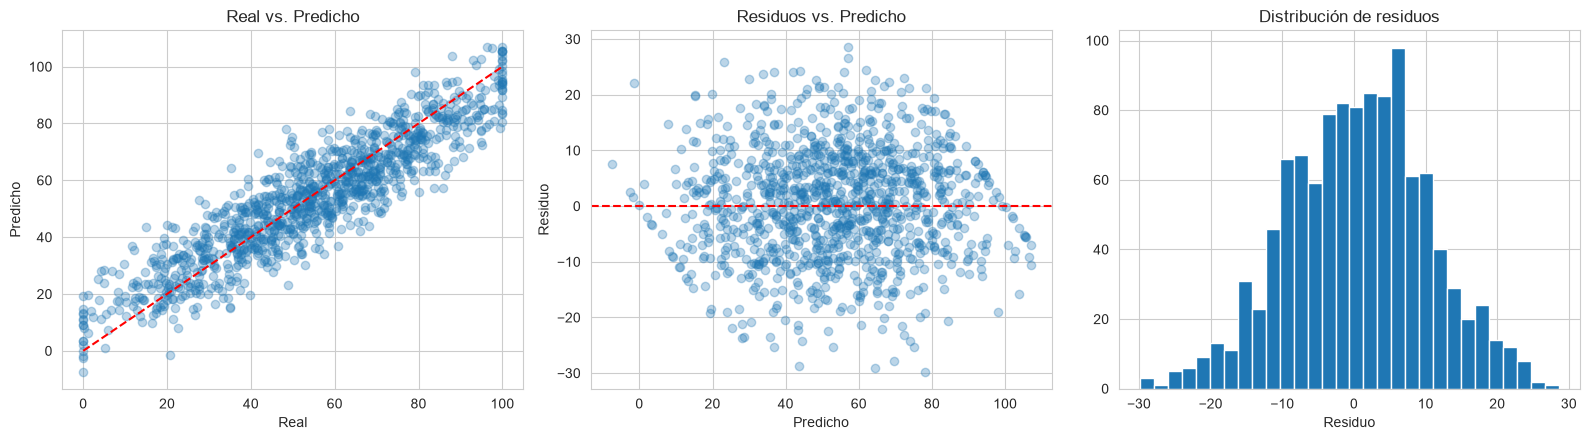

Predicciones fuera de 0-100: 20


In [34]:
residuos = y_test - pred_lr
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ax[0].scatter(y_test, pred_lr, alpha=0.3)
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
ax[0].set(xlabel="Real", ylabel="Predicho", title="Real vs. Predicho")

ax[1].scatter(pred_lr, residuos, alpha=0.3)
ax[1].axhline(0, color="r", ls="--")
ax[1].set(xlabel="Predicho", ylabel="Residuo", title="Residuos vs. Predicho")

ax[2].hist(residuos, bins=30)
ax[2].set(xlabel="Residuo", title="Distribución de residuos")
plt.tight_layout(); plt.show()

print("Predicciones fuera de 0-100:", int(((pred_lr < 0) | (pred_lr > 100)).sum()))

## 11. Conclusiones

**Sobre la limpieza:**
- El dataset tenía **2% de vacíos por columna**, pero dispersos en **21.6% de las filas**.
- Se **reconstruyeron 138 valores de `burnout_level`** con la regla Low ≤ 35 < Medium ≤ 70 < High, verificada al 100%. Así no se perdieron filas por esa columna.
- Se eliminaron las **140 filas sin `stress_level`** (no se puede inventar la respuesta).
- Las filas con vacíos en las predictoras se eliminaron con **`dropna()`**: el modelo usa **5.606 filas (80% del original), todas con datos reales**.
- Se detectó una **inconsistencia edad/experiencia** (~1.960 personas "empezaron a trabajar" antes de los 18, algunas siendo niños). Se comprobó que **no afecta** al modelo: sin esas filas, el R² pasa de 0.8234 a 0.8228.

**Sobre el modelo:**
- La **regresión lineal** es el mejor modelo: explica el **~82% del estrés** (R² ≈ 0.82) con un error promedio de **~8 puntos sobre 100**. Random Forest queda cerca (R² ≈ 0.79) y el árbol simple atrás (R² ≈ 0.59). Las relaciones son mayormente lineales.
- **Lo que más pesa** (los tres métodos coinciden en el top 5): **horas de trabajo, bugs por día, reuniones** (suben el estrés), **horas de sueño** (lo baja) y **cafeína** (sube). Luego el ejercicio (baja).
- **En unidades reales**, manteniendo lo demás constante: cada hora extra de trabajo suma **~4.9 puntos** de estrés, cada reunión **~2.8**, cada unidad de cafeína **~2.0**, cada bug **~1.9**; cada hora de sueño resta **~3.8** y cada hora de ejercicio **~5.1**.
  - El ejercicio tiene el coeficiente más grande por hora, pero en el ranking queda más abajo porque la gente varía poco en ejercicio (0 a 2 h): su impacto total en el dataset es menor.
- Edad, experiencia, commits y tiempo de pantalla **prácticamente no influyen** en el modelo.

**Limitaciones:**
- Con `dropna()` se pierde ~20% de las filas. Quedan más de 5.600, suficientes, pero el modelo no sirve para predecir a alguien con datos incompletos.
- `daily_work_hours` y `screen_time` están muy correlacionadas (VIF ≈ 7): no se puede separar bien su efecto individual. Por eso la pantalla correlaciona alto con el estrés pero casi no pesa en el modelo.
- La regresión lineal puede predecir fuera de 0–100 (pasa en pocos casos del test).
- Son **asociaciones, no causalidad**.
- Sin p-valores: la importancia se respalda cruzando tres métodos.
- `burnout_level` se excluyó de las predictoras para evitar data leakage.